# 29. KAIST three-sensor calibration: augmentation robustness map

**Inference-only, no optimization or checkpoint saving.** Load `002.10` and evaluate the same fixed held-out KAIST physical windows under controlled augmentation strengths. One augmentation family is changed per sweep; prior corrections remain identical between strengths. Two symmetric ± prior branches are evaluated.

**Questions:** where does the correction begin to deteriorate? Does the model correct near-zero errors without false updates? Is a new training augmentation justified at all?

The notebook separates **calibration-prior errors** (the task the NN should solve), **physical true-calibration changes**, **sensor-frame relabeling**, and **measurement corruption/rate reduction**. Rotation accuracy is measured both as correction-vector error and as actual one-step SO(3) geodesic error; tau errors are in milliseconds. Translation is not supervised and is reported only as a diagnostic.

The exact-angle frame and true-calibration transformations below reuse the formulas from `obscalib.augmentations`. They are *diagnostic controls*, not additional training augmentation implementations. Frame randomization currently samples Haar SO(3) rotations, so this notebook adds a continuous angle control for plotting.


## 1. Repository imports and model setup

In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint
from obscalib.training.metrics_logger import MetricsLogger
import gc

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)

from obscalib.augmentations.noise import MeasurementNoiseAugmenter
from obscalib.augmentations.sampling_rate import SamplingRateAugmenter
from obscalib.augmentations.frame_randomization import _randomize_calibration, _randomize_stream
from obscalib.augmentations.true_calibration import _render_static_truth_change, _relative_frame
from obscalib.augmentations.config import VectorNoiseConfig, SE3NoiseConfig
from obscalib.data.structures import CalibrationTargetBatch, MeasurementType, SensorStreamBatch
from obscalib.geometry.lie import so3_exp, so3_log
import csv
import json
from collections import defaultdict


Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2. Diagnostic settings

The source checkpoint and model exactly match notebook 28. A small fixed subset makes the first run practical. Set `WINDOWS_PER_SEQUENCE=64` later for stronger statistics.

In [2]:
RUN_NAME = "kaist_augmentation_robustness_002.10"

# Specify the exact previous successful checkpoint; this is a weights-only initialization.
# Change SOURCE_RUN_NAME to "kaist_pooled_calibration_paired_002.9_student" if that is your actual saved run directory.
SOURCE_RUN_NAME = "kaist_pooled_calibration_paired_002.10_fine_coarse"
RESUME_CHECKPOINT = ROOT / "runs" / SOURCE_RUN_NAME / "best.pt"

RANDOM_SEED = 12345
TRAIN_PAIR_SEED = 23456
VALIDATION_PAIR_SEED = 34567
TEST_PAIR_SEED = 45678
VISUALIZATION_PAIR_SEED = 56789

DEVICE_NAME = "cuda"
DEVICE = torch.device("cuda" if DEVICE_NAME == "auto" and torch.cuda.is_available() else DEVICE_NAME)
MODEL_DTYPE = torch.float32

CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
CALIBRATION_CONTEXT_DIM = 7

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700

BATCH_SIZE = 16
NUM_WORKERS = 0
DROP_LAST_TRAIN = True

NUM_EPOCHS = 50
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
CHECKPOINT_EVERY_EPOCHS = 3
PRINT_EVERY_BATCHES = 500
LR_REDUCTION_FACTOR = 0.5
LR_PATIENCE_EPOCHS = 8

MEASUREMENT_DIM = 6
TOKEN_INPUT_DIM = MEASUREMENT_DIM + 2
D_MODEL = 128
N_HEADS = 8
NUM_TRANSFORMER_LAYERS = 12
DIM_FEEDFORWARD = 512
TRANSFORMER_DROPOUT = 0.0
NUM_SUMMARY_TOKENS = 1

POOLER_N_HEADS = 8
POOLER_DROPOUT = 0.0
MLP_HIDDEN_DIMS = (256, 128)
SHARED_FEATURE_DIM = 128
MLP_DROPOUT = 0.0
HEAD_HIDDEN_DIMS = (128, 64)
HEAD_DROPOUT = 0.0

CORRECTION_LOSS_TYPE = "mse"
ROTATION_LOSS_SCALE_RAD = np.deg2rad(5.0)
TRANSLATION_LOSS_SCALE_M = 0.05
TIME_OFFSET_LOSS_SCALE_S = 0.050
ROTATION_LOSS_WEIGHT = 2.0
TRANSLATION_LOSS_WEIGHT = 1.0
TIME_OFFSET_LOSS_WEIGHT = 1.0
PAIR_LOSS_WEIGHT = 0.1
TRUTH_ANCHOR_LOSS_WEIGHT = 1.0   # Truth branch is not executed, so contributes zero.
CHANGE_EVENT_LOSS_WEIGHT = 0.0
CHANGE_TIME_LOSS_WEIGHT = 0.0

# One paired-prior distribution for every example; no fine/coarse branch.
PAIR_ROTATION_MAX_RAD = np.deg2rad(60.0)
PAIR_ROTATION_SCALE_RAD = np.deg2rad(30.0)
PAIR_TIME_OFFSET_MAX_S = 0.500
PAIR_TIME_OFFSET_SCALE_S = 0.250
STUDENT_T_DEGREES_OF_FREEDOM = 3
PAIR_TRANSLATION_MAX_M = 0.02  # Legacy disabled generic-prior config only.

# Physically consistent true-calibration augmentation, independent of the prior error.
TRUE_CALIBRATION_ROTATION_MAX_RAD = np.deg2rad(180.0)
TRUE_CALIBRATION_TIME_OFFSET_MAX_S = 0.030


# Controls for the diagnostic, not training.
WINDOWS_PER_SEQUENCE = 24
EVAL_BATCH_SIZE = 8
EVAL_SEED = 826410
EVAL_SPLIT = "test"                  # "validation" or "test"
SAVE_RESULTS = True
RESULTS_DIR = ROOT / "runs" / RUN_NAME

# Fixed prior probe when testing the effects of contextual augmentation.
PROBE_ROTATION_DEG = 5.0
PROBE_TAU_MS = 50.0

# Exact-angle sweeps. Prior targets are rotation only / tau only in their own sweeps.
PRIOR_ROTATION_LEVELS_DEG = (0, 0.5, 1, 2, 5, 10, 20, 40, 60, 90)
PRIOR_TAU_LEVELS_MS = (0, 1, 2, 5, 10, 20, 50, 100, 250, 500, 750)
TRUE_ROTATION_LEVELS_DEG = (0, 15, 30, 60, 90, 120, 150, 180)
TRUE_TAU_LEVELS_MS = (0, 10, 30, 50, 100)
FRAME_ROTATION_LEVELS_DEG = (0, 15, 30, 60, 90, 120, 150, 180)
NOISE_LEVELS = (0, 0.25, 0.5, 1.0, 2.0, 4.0)  # Multiplier on documented base stds.
IMU_RATE_FLOORS_HZ = (0, 90, 75, 50, 25, 10)
LIDAR_RATE_FLOORS_HZ = (0, 9, 7, 5, 3, 2)

SWEEPS = {
    "prior_rotation": PRIOR_ROTATION_LEVELS_DEG,
    "prior_tau": PRIOR_TAU_LEVELS_MS,
    "true_rotation": TRUE_ROTATION_LEVELS_DEG,
    "true_tau": TRUE_TAU_LEVELS_MS,
    "frame_rotation": FRAME_ROTATION_LEVELS_DEG,
    "imu_noise": NOISE_LEVELS,
    "lidar_noise": NOISE_LEVELS,
    "imu_bias": NOISE_LEVELS,
    "imu_rate": IMU_RATE_FLOORS_HZ,
    "lidar_rate": LIDAR_RATE_FLOORS_HZ,
}

if not RESUME_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Missing source checkpoint: {RESUME_CHECKPOINT}")
print("Loading source:", RESUME_CHECKPOINT)
print("Fixed prior probe:", PROBE_ROTATION_DEG, "degrees and", PROBE_TAU_MS, "ms")


Loading source: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.10_fine_coarse/best.pt
Fixed prior probe: 5.0 degrees and 50.0 ms


## 3. Original KAIST train/validation/test split and rig

These cells are copied from notebook 28 without changing the dataset or extrinsics.

In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)


train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']


In [4]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")

# The 3-sensor experiment must never silently fall back to 2 sensors.
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing required right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
test_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TEST_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

for split_name, dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"{split_name} dataset has calibration keys {dataset.calibration_keys}, expected {CALIBRATION_KEYS}")

print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())


KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiD

## 4. Original pooled architecture, loaded without optimizer

Weights and preprocessing match `002.10`; no trained parameters are modified.

In [5]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation="gelu"),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation="gelu", dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(
        n_heads=POOLER_N_HEADS,
        dropout=POOLER_DROPOUT,
        calibration_context_dim=0,           # CALIBRATION_CONTEXT_DIM
    ),

    head=PooledCalibrationHeadConfig(
        calibration_context_dim=0,
        hidden_dims=HEAD_HIDDEN_DIMS,
        activation="gelu",
        dropout=HEAD_DROPOUT,
    ),
)

geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)
model = PooledCalibrationModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
calibration_updater = CalibrationUpdater()
window_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=model, calibration_updater=calibration_updater)

# if not getattr(model, "uses_calibration_context", False):
#     raise RuntimeError("This experiment requires the pooled model to use numeric calibration context.")

print("Loaded architecture:", type(model).__name__)
print()
print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))
print("Trainable parameters:", sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))
print("Pooler calibration context dim:", model.pooler.calibration_context_dim)
print("Head calibration context dim:", model.head.config.calibration_context_dim)


Loaded architecture: PooledCalibrationModel

Parameters: 2554505
Trainable parameters: 2554505
Pooler calibration context dim: 0
Head calibration context dim: 0


In [6]:
source_checkpoint = load_training_checkpoint(RESUME_CHECKPOINT, model=model, map_location=DEVICE, restore_rng_state=False)
model.eval()
for parameter in model.parameters():
    parameter.requires_grad_(False)
print("Checkpoint epoch:", source_checkpoint.get("epoch"))
print("Model parameters:", sum(x.numel() for x in model.parameters()))


Checkpoint epoch: 9
Model parameters: 2554505


## 5. Fixed held-out selection and deterministic seeds

The same windows, selected calibration keys, perturbation directions and ± branches are used at every strength. `Urban38` and `Urban39` are held out. The evaluation does **not** resample physical windows per condition.

In [7]:
EVAL_DATASET = test_dataset if EVAL_SPLIT == "test" else val_dataset
EVAL_NAMES = TEST_NAMES if EVAL_SPLIT == "test" else VAL_NAMES

def select_fixed_indices(dataset, names, per_sequence):
    output = []
    for name in names:
        possible = list(dataset.window_indices_for_sequence(name))
        take = min(per_sequence, len(possible))
        output.extend(int(possible[i]) for i in np.linspace(0, len(possible) - 1, take, dtype=int))
    return output

# Each selected sensor receives comparable numbers of active perturbations.
EVAL_INDICES = select_fixed_indices(EVAL_DATASET, EVAL_NAMES, WINDOWS_PER_SEQUENCE)
print(f"Evaluation split={EVAL_SPLIT}, N={len(EVAL_INDICES)}, indices={EVAL_INDICES[:5]}...")
assert len(EVAL_INDICES) >= 6

def augmentation_generator(seed):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))

def replace_window(window, *, streams=None, calibration=None, targets=None):
    return WindowBatch(
        streams=dict(window.streams) if streams is None else streams,
        current_calibration=dict(window.current_calibration) if calibration is None else calibration,
        metadata=dict(window.metadata),
        targets=window.targets if targets is None else targets,
        dataset_indices=window.dataset_indices,
    )

def truth_targets(calibration):
    return {key: CalibrationTargetBatch(next_transform=state.transform, next_time_offset=state.time_offset) for key, state in calibration.items()}

# Balanced one-sensor-per-sample assignment is fixed across all sweeps.
def selected_sensor_ids(batch_indices):
    return torch.tensor([EVAL_INDICES.index(int(i)) % len(CALIBRATION_KEYS) for i in batch_indices], device=DEVICE)

def fixed_directions(batch_size, seed, *, dtype=MODEL_DTYPE):
    g = augmentation_generator(seed)
    direction = torch.randn(batch_size, 3, device=DEVICE, dtype=dtype, generator=g)
    return direction / torch.linalg.vector_norm(direction, dim=-1, keepdim=True).clamp_min(1e-12)


Evaluation split=test, N=48, indices=[0, 15, 30, 45, 60]...


## 6. Controlled physical-context augmentations

These functions change *physical truth and measurements consistently* and then regenerate targets. The candidate prior is applied separately afterward, so no ground-truth information is leaked into the model. Frame randomization is a change of sensor coordinate description, not a new calibration error.

In [8]:
def exact_physical_context(base_window, family, amount, seed):
    """Exact-angle true calibration / frame changes; source formulas are reused."""
    if family not in {"true_rotation", "true_tau", "frame_rotation"} or amount == 0:
        return replace_window(base_window, targets=truth_targets(base_window.current_calibration))

    new_calibration = {}
    relative_frames = {}
    time_shifts = {}
    frame_matrices = {}

    for index, key in enumerate(CALIBRATION_KEYS):
        state = base_window.current_calibration[key]
        batch_size = state.transform.shape[0]
        dirs = fixed_directions(batch_size, seed + 101 * index, dtype=state.transform.dtype)
        T = state.transform
        new_T = T.clone()
        tau_shift = torch.zeros_like(state.time_offset)

        if family == "true_rotation":
            new_T[:, :3, :3] = so3_exp(dirs * np.deg2rad(amount)) @ T[:, :3, :3]
        elif family == "true_tau":
            gen = augmentation_generator(seed + 791 * index)
            signs = (torch.randint(0, 2, (batch_size, 1), device=DEVICE, generator=gen) * 2 - 1).to(T.dtype)
            tau_shift = signs * (amount / 1000.0)
        elif family == "frame_rotation":
            A = torch.zeros_like(T)
            A[:, :3, :3] = so3_exp(dirs * np.deg2rad(amount))
            A[:, 3, 3] = 1.0
            new_T = T @ A
            frame_matrices[key] = A

        new_calibration[key] = CalibrationState(transform=new_T, time_offset=state.time_offset + tau_shift)
        relative_frames[key] = _relative_frame(T, new_T)
        time_shifts[key] = tau_shift

    streams = {}
    for stream_key, stream in base_window.streams.items():
        metadata = base_window.metadata[stream_key]
        key = metadata.calibration_key
        if family == "frame_rotation":
            streams[stream_key] = _randomize_stream(stream, metadata.geometry_type, frame_matrices[key])
        else:
            streams[stream_key] = _render_static_truth_change(stream, metadata.geometry_type, relative_frames[key], time_shifts[key])

    return replace_window(base_window, streams=streams, calibration=new_calibration, targets=truth_targets(new_calibration))


def measurement_context(base_window, family, amount, seed):
    """Apply an existing noise or sampling-rate augmenter, without altering truth."""
    if amount == 0:
        return replace_window(base_window, targets=truth_targets(base_window.current_calibration)), {}

    if family in ("imu_noise", "lidar_noise", "imu_bias"):
        # At multiplier 1: gyro noise=0.1 deg/s; accel=0.05 m/s²;
        # LiDAR relative pose rotation=0.05 deg and translation=0.5 cm.
        vector = {}
        se3 = {}
        if family == "imu_noise":
            vector = {
                MeasurementType.IMU_GYROSCOPE: VectorNoiseConfig(gaussian_std=np.deg2rad(0.1) * amount),
                MeasurementType.IMU_ACCELEROMETER: VectorNoiseConfig(gaussian_std=0.05 * amount),
            }
        elif family == "imu_bias":
            vector = {
                MeasurementType.IMU_GYROSCOPE: VectorNoiseConfig(window_bias_std=np.deg2rad(0.03) * amount),
                MeasurementType.IMU_ACCELEROMETER: VectorNoiseConfig(window_bias_std=0.02 * amount),
            }
        else:
            se3 = {MeasurementType.LIDAR_POSE: SE3NoiseConfig(rotation_std=np.deg2rad(0.05) * amount, translation_std=0.005 * amount)}
        augmenter = MeasurementNoiseAugmenter(NoiseAugmentationConfig(enabled=True, vector_by_type=vector, se3_by_type=se3))
        augmented, biases = augmenter(replace_window(base_window, targets=truth_targets(base_window.current_calibration)), generator=augmentation_generator(seed))
        return augmented, {}

    if family in ("imu_rate", "lidar_rate"):
        config = SamplingRateAugmentationConfig(
            enabled=True,
            minimum_imu_frequency_hz=float(amount) if family == "imu_rate" else None,
            minimum_lidar_frequency_hz=float(amount) if family == "lidar_rate" else None,
            imu_probability=1.0,
            lidar_probability=1.0,
        )
        output, frequencies, applied = SamplingRateAugmenter(config)(replace_window(base_window, targets=truth_targets(base_window.current_calibration)), generator=augmentation_generator(seed))
        observed = []
        for key in frequencies:
            mask = applied[key].flatten().bool()
            if mask.any():
                observed.extend(frequencies[key].flatten()[mask].detach().cpu().numpy().tolist())
        return output, {"achieved_hz": float(np.mean(observed)) if observed else float("nan"), "changed": len(observed)}

    raise ValueError(f"Unsupported measurement augmentation: {family}")


def make_context(base_window, family, amount, seed):
    if family in ("true_rotation", "true_tau", "frame_rotation"):
        return exact_physical_context(base_window, family, amount, seed), {}
    if family in ("imu_noise", "lidar_noise", "imu_bias", "imu_rate", "lidar_rate"):
        return measurement_context(base_window, family, amount, seed)
    if family in ("prior_rotation", "prior_tau", "baseline"):
        return replace_window(base_window, targets=truth_targets(base_window.current_calibration)), {}
    raise ValueError(f"Unknown sweep: {family}")


## 7. Fixed calibration-prior pairs

For every physical window, exactly one of the three sensors receives the correction target. The +δ and −δ branches share physical data. When sweeping prior rotation or tau, the other component is zero; all other sweeps use fixed 5° and 50 ms correction probes.

In [9]:
def make_fixed_prior_pair(context_window, family, amount, batch_indices, seed):
    batch_size = len(batch_indices)
    active_id = selected_sensor_ids(batch_indices)
    delta_xi = {key: torch.zeros(batch_size, 6, device=DEVICE, dtype=MODEL_DTYPE) for key in CALIBRATION_KEYS}
    delta_tau = {key: torch.zeros(batch_size, 1, device=DEVICE, dtype=MODEL_DTYPE) for key in CALIBRATION_KEYS}
    rot_deg = amount if family == "prior_rotation" else (0.0 if family == "prior_tau" else PROBE_ROTATION_DEG)
    tau_ms = amount if family == "prior_tau" else (0.0 if family == "prior_rotation" else PROBE_TAU_MS)
    directions = fixed_directions(batch_size, seed + 191)
    generator = augmentation_generator(seed + 233)
    signed_tau = (torch.randint(0, 2, (batch_size, 1), device=DEVICE, generator=generator) * 2 - 1).to(MODEL_DTYPE) * (tau_ms / 1000.0)

    for sensor_index, key in enumerate(CALIBRATION_KEYS):
        choose = active_id == sensor_index
        delta_xi[key][choose, :3] = directions[choose] * np.deg2rad(rot_deg)
        delta_tau[key][choose] = signed_tau[choose]

    truth = context_window.current_calibration
    positive = apply_prior_perturbation(truth, delta_xi, delta_tau)
    negative = apply_prior_perturbation(truth, {key: -v for key, v in delta_xi.items()}, {key: -v for key, v in delta_tau.items()})
    plus = replace_window(context_window, calibration=positive)
    minus = replace_window(context_window, calibration=negative)
    return plus, minus, active_id, delta_xi, delta_tau


def test_pair_semantics():
    indices = EVAL_INDICES[:EVAL_BATCH_SIZE]
    base = window_batch_to(collate_windows([EVAL_DATASET[i] for i in indices]), DEVICE, dtype=MODEL_DTYPE)
    context, _ = make_context(base, "true_rotation", 150.0, EVAL_SEED + 50)
    plus, minus, active_id, deltas, taus = make_fixed_prior_pair(context, "baseline", 0, indices, EVAL_SEED + 50)
    for key in CALIBRATION_KEYS:
        true_T = context.current_calibration[key].transform
        error_positive = se3_log(true_T @ torch.linalg.inv(plus.current_calibration[key].transform))
        error_negative = se3_log(true_T @ torch.linalg.inv(minus.current_calibration[key].transform))
        torch.testing.assert_close(error_positive, -deltas[key], atol=1e-4, rtol=1e-4)
        torch.testing.assert_close(error_negative, deltas[key], atol=1e-4, rtol=1e-4)
        torch.testing.assert_close(plus.current_calibration[key].time_offset + minus.current_calibration[key].time_offset, 2 * context.current_calibration[key].time_offset, atol=1e-5, rtol=1e-5)
    print("Physical context / paired prior / correction targets: PASS")

test_pair_semantics()


Physical context / paired prior / correction targets: PASS


## 8. Metrics: true one-step geodesic error, correction error and false updates

One-step rotation error is measured *after the predicted update*, with the calibration truth held fixed. For unperturbed sensors the output is a false-update diagnostic. Translation predictions are not applied, since translation was not trained.

In [10]:
def metrics_for_one_branch(window, output, context_window, active_id):
    records = []
    for sensor_index, key in enumerate(CALIBRATION_KEYS):
        prediction = output.predictions[key]
        prior = window.current_calibration[key]
        truth = context_window.current_calibration[key]
        active = (active_id == sensor_index)
        if not active.any():
            continue

        R_prior = prior.transform[:, :3, :3]
        R_true = truth.transform[:, :3, :3]
        # Left-action convention matches CalibrationUpdater and prior sampling.
        R_updated = so3_exp(prediction.delta_xi[:, :3]) @ R_prior
        rotation_before = torch.rad2deg(torch.linalg.vector_norm(so3_log(R_true @ R_prior.transpose(-1, -2)), dim=-1))
        rotation_after = torch.rad2deg(torch.linalg.vector_norm(so3_log(R_true @ R_updated.transpose(-1, -2)), dim=-1))

        correction_true = se3_log(truth.transform @ torch.linalg.inv(prior.transform))[:, :3]
        correction_mae = torch.rad2deg(torch.linalg.vector_norm(prediction.delta_xi[:, :3] - correction_true, dim=-1))
        tau_before = 1000.0 * torch.abs(prior.time_offset[:, 0] - truth.time_offset[:, 0])
        tau_after = 1000.0 * torch.abs(prior.time_offset[:, 0] + prediction.delta_tau[:, 0] - truth.time_offset[:, 0])
        false_translation = 100.0 * torch.linalg.vector_norm(prediction.delta_xi[:, 3:], dim=-1)

        # Transfer the few scalar diagnostics once, avoiding per-sample GPU synchronizations.
        active_cpu = active.detach().cpu().numpy().astype(bool)
        measurements = {
            "rotation_before_deg": rotation_before.detach().cpu().numpy(),
            "rotation_after_deg": rotation_after.detach().cpu().numpy(),
            "rotation_correction_error_deg": correction_mae.detach().cpu().numpy(),
            "rotation_improved": (rotation_after + 1e-5 < rotation_before).to(rotation_after.dtype).detach().cpu().numpy(),
            "tau_before_ms": tau_before.detach().cpu().numpy(),
            "tau_after_ms": tau_after.detach().cpu().numpy(),
            "false_translation_cm": false_translation.detach().cpu().numpy(),
        }
        for j in np.flatnonzero(active_cpu):
            records.append({"sensor": key, **{name: float(values[j]) for name, values in measurements.items()}})
    return records


def summarize_records(records, family, amount, changed_rates):
    output = []
    for key in CALIBRATION_KEYS:
        group = [r for r in records if r["sensor"] == key]
        assert group, f"No selected active examples for {key}"
        row = {"sweep": family, "level": float(amount), "sensor": key, "n": len(group)}
        for field in group[0]:
            if field != "sensor":
                row[field] = float(np.mean([r[field] for r in group]))
        row["rate_achieved_hz"] = float(np.nanmean(changed_rates)) if changed_rates else float("nan")
        output.append(row)
    return output


## 9. Inference sweeps with shared windows and perturbations

The benchmark avoids data leakage: it never reads perturbed calibration truth as an NN input. Truth is used only for constructing targets and evaluating predictions. **Each sweep varies one augmentation at a time.** Rate sweeps report achieved frequencies because `SamplingRateAugmenter` samples targets uniformly between its lower bound and each source frequency.

In [11]:
def evaluate_one_level(family, amount):
    all_records = []
    observed_rates = []
    model.eval()
    with torch.inference_mode():
        for batch_start in range(0, len(EVAL_INDICES), EVAL_BATCH_SIZE):
            indices = EVAL_INDICES[batch_start:batch_start + EVAL_BATCH_SIZE]
            base = collate_windows([EVAL_DATASET[i] for i in indices])
            base = window_batch_to(base, DEVICE, dtype=MODEL_DTYPE)
            # Fixed seeds across levels keep axes, calibration selection and measurement-noise draws matched.
            seed = EVAL_SEED + 10007 * batch_start
            context, extra = make_context(base, family, float(amount), seed)
            if "achieved_hz" in extra and np.isfinite(extra["achieved_hz"]):
                observed_rates.append(extra["achieved_hz"])
            plus, minus, active_id, _, _ = make_fixed_prior_pair(context, family, float(amount), indices, seed)
            for window in (plus, minus):
                result = window_step(window)
                all_records.extend(metrics_for_one_branch(window, result.model_output, context, active_id))
    return summarize_records(all_records, family, amount, observed_rates)


def run_sweep(family):
    levels = SWEEPS[family]
    output = []
    for level in levels:
        rows = evaluate_one_level(family, level)
        output.extend(rows)
        print(f"{family:16s} {level:>7g} | " + " | ".join(
            f"{row['sensor']}: rot={row['rotation_after_deg']:.2f}°, tau={row['tau_after_ms']:.1f}ms" for row in rows
        ))
    return output

ALL_RESULTS = []
print("Quick baseline, before the complete battery")
ALL_RESULTS.extend(run_sweep("prior_rotation")[:])


Quick baseline, before the complete battery
prior_rotation         0 | imu: rot=0.49°, tau=1.3ms | lidar: rot=0.41°, tau=4.5ms | lidar_right: rot=1.20°, tau=6.1ms
prior_rotation       0.5 | imu: rot=0.62°, tau=1.3ms | lidar: rot=0.50°, tau=4.5ms | lidar_right: rot=1.27°, tau=6.1ms
prior_rotation         1 | imu: rot=0.93°, tau=1.3ms | lidar: rot=0.72°, tau=4.6ms | lidar_right: rot=1.42°, tau=6.1ms
prior_rotation         2 | imu: rot=1.66°, tau=1.4ms | lidar: rot=1.22°, tau=4.7ms | lidar_right: rot=1.80°, tau=6.2ms
prior_rotation         5 | imu: rot=3.72°, tau=1.6ms | lidar: rot=2.80°, tau=5.4ms | lidar_right: rot=3.12°, tau=6.9ms
prior_rotation        10 | imu: rot=4.85°, tau=2.7ms | lidar: rot=5.32°, tau=7.2ms | lidar_right: rot=5.25°, tau=8.7ms
prior_rotation        20 | imu: rot=3.71°, tau=3.3ms | lidar: rot=10.39°, tau=10.6ms | lidar_right: rot=9.51°, tau=11.4ms
prior_rotation        40 | imu: rot=4.45°, tau=6.3ms | lidar: rot=20.97°, tau=15.1ms | lidar_right: rot=18.89°, tau=14.3

## 10. Evaluate all remaining augmentation families

For a quick smoke test, set `SWEEPS_TO_RUN` to only `("frame_rotation", "imu_noise")`. The cell is safe to rerun; it replaces previous rows for each selected sweep.

In [12]:
SWEEPS_TO_RUN = (
    "prior_tau", "true_rotation", "true_tau", "frame_rotation",
    "imu_noise", "lidar_noise", "imu_bias", "imu_rate", "lidar_rate",
)

for family in SWEEPS_TO_RUN:
    ALL_RESULTS = [row for row in ALL_RESULTS if row["sweep"] != family]
    ALL_RESULTS.extend(run_sweep(family))

print("Completed rows:", len(ALL_RESULTS))


prior_tau              0 | imu: rot=0.49°, tau=1.3ms | lidar: rot=0.41°, tau=4.5ms | lidar_right: rot=1.20°, tau=6.1ms
prior_tau              1 | imu: rot=0.49°, tau=1.5ms | lidar: rot=0.41°, tau=4.6ms | lidar_right: rot=1.20°, tau=6.1ms
prior_tau              2 | imu: rot=0.50°, tau=2.0ms | lidar: rot=0.41°, tau=4.8ms | lidar_right: rot=1.20°, tau=6.3ms
prior_tau              5 | imu: rot=0.53°, tau=3.9ms | lidar: rot=0.41°, tau=5.8ms | lidar_right: rot=1.20°, tau=7.0ms
prior_tau             10 | imu: rot=0.69°, tau=6.4ms | lidar: rot=0.42°, tau=8.4ms | lidar_right: rot=1.20°, tau=8.3ms
prior_tau             20 | imu: rot=1.16°, tau=9.0ms | lidar: rot=0.45°, tau=14.1ms | lidar_right: rot=1.22°, tau=12.1ms
prior_tau             50 | imu: rot=2.58°, tau=4.8ms | lidar: rot=0.51°, tau=25.0ms | lidar_right: rot=1.31°, tau=20.8ms
prior_tau            100 | imu: rot=2.98°, tau=4.1ms | lidar: rot=0.57°, tau=20.6ms | lidar_right: rot=1.45°, tau=16.9ms
prior_tau            250 | imu: rot=3.14°,

## 11. Magnitude-response plots

For each augmentation, the left column plots rotation geodesic error **after applying the update**; the right column plots tau absolute error. One line per sensor. Baseline (zero augmentation strength) is displayed for reference. A separate figure compares one-step improvement and physical prior error, so a seemingly low MAE cannot hide an ineffective update.

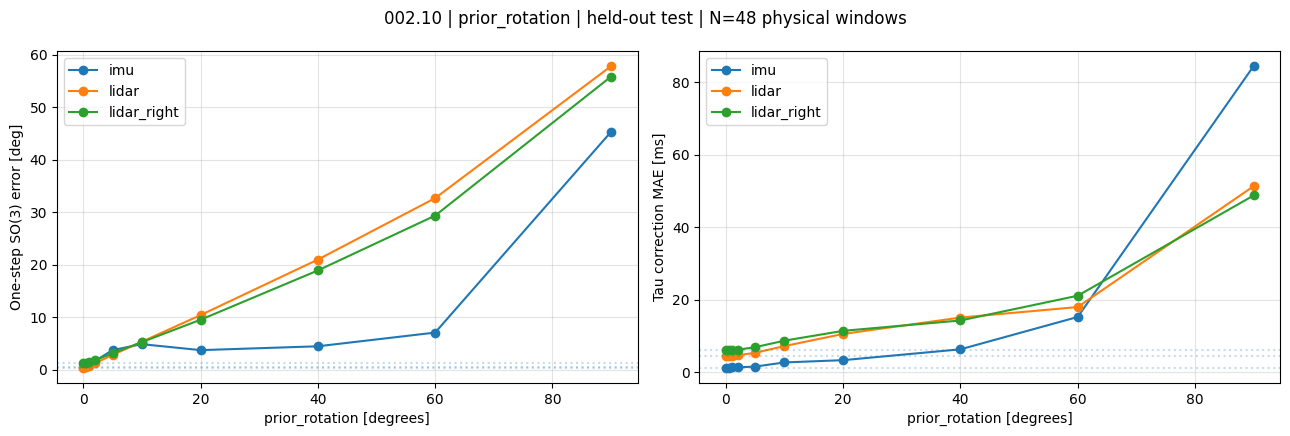

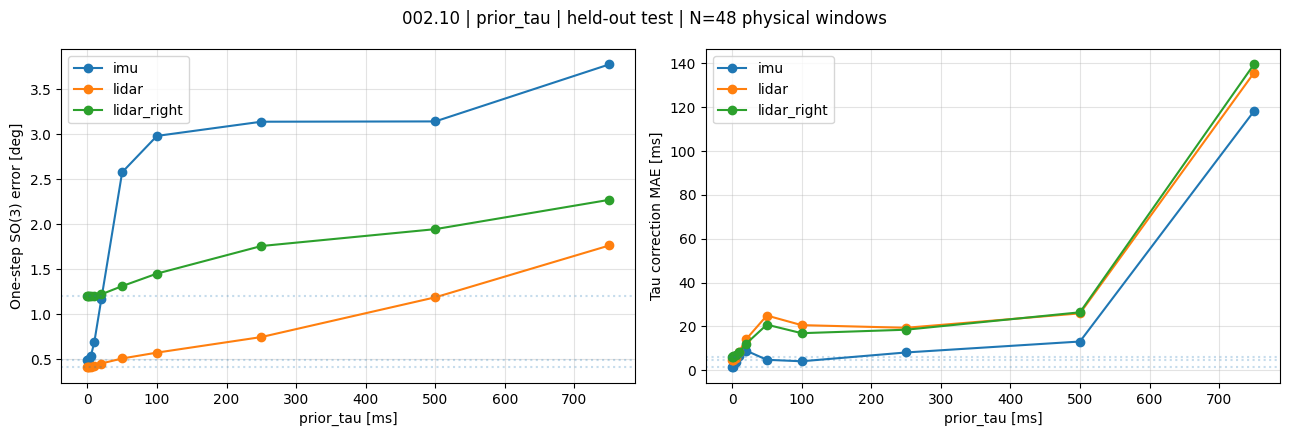

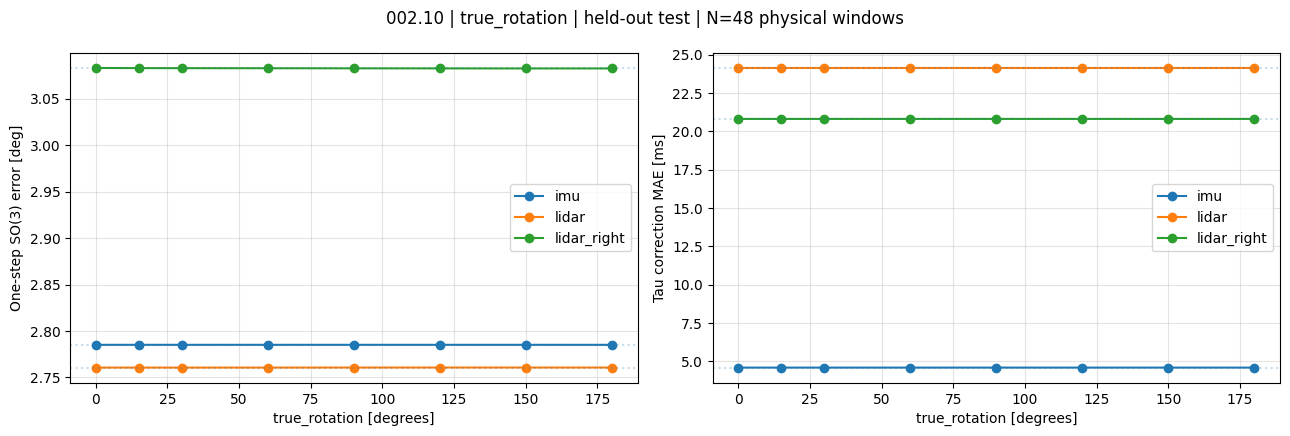

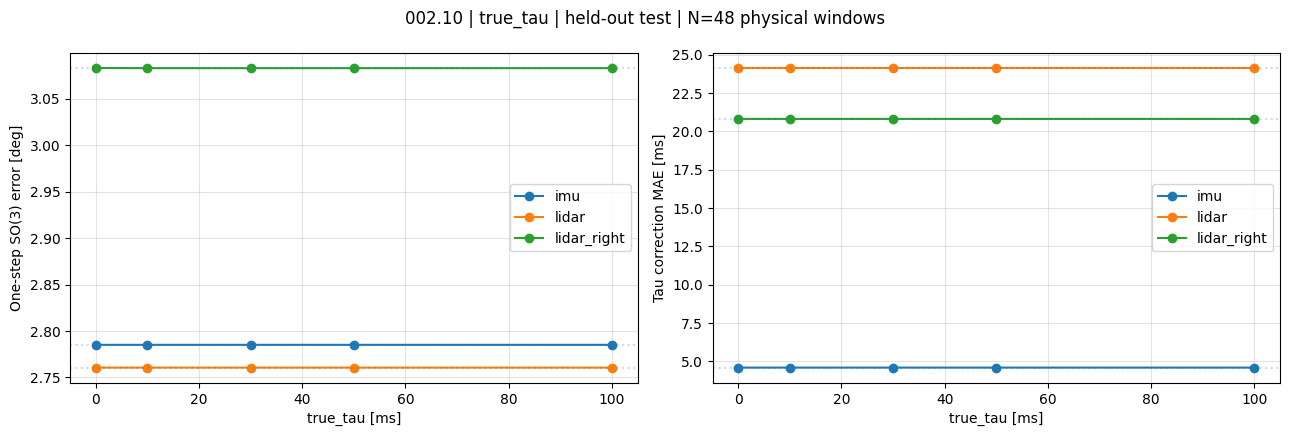

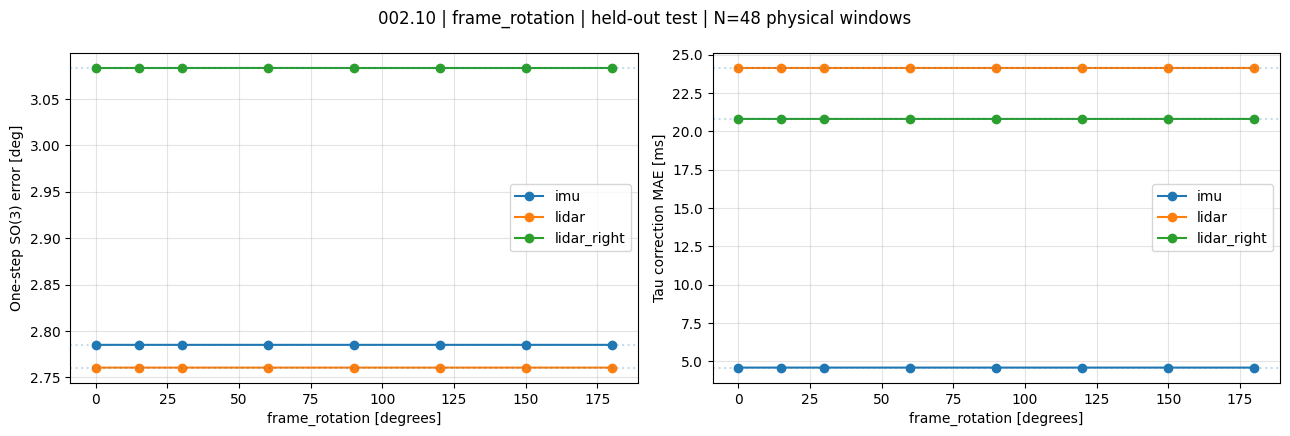

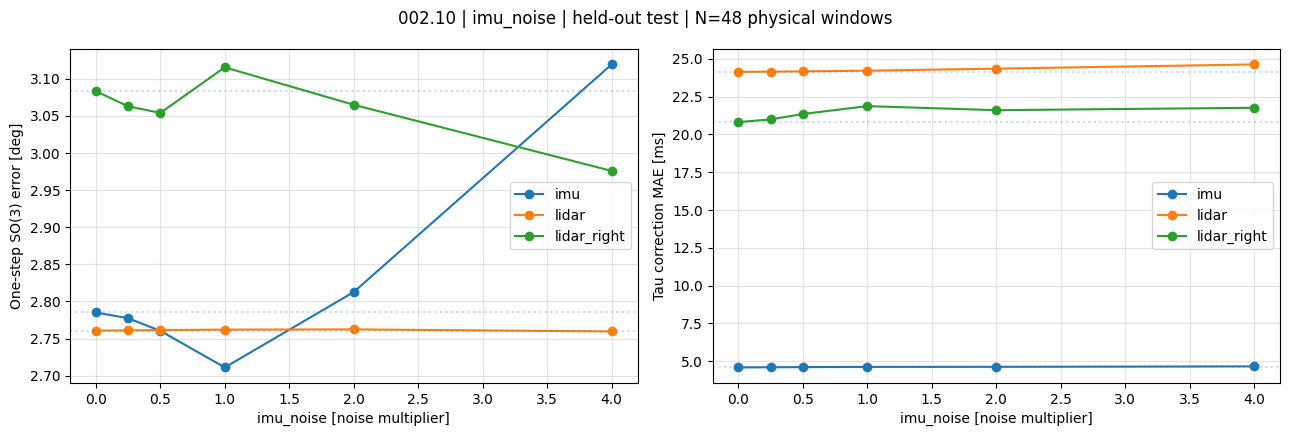

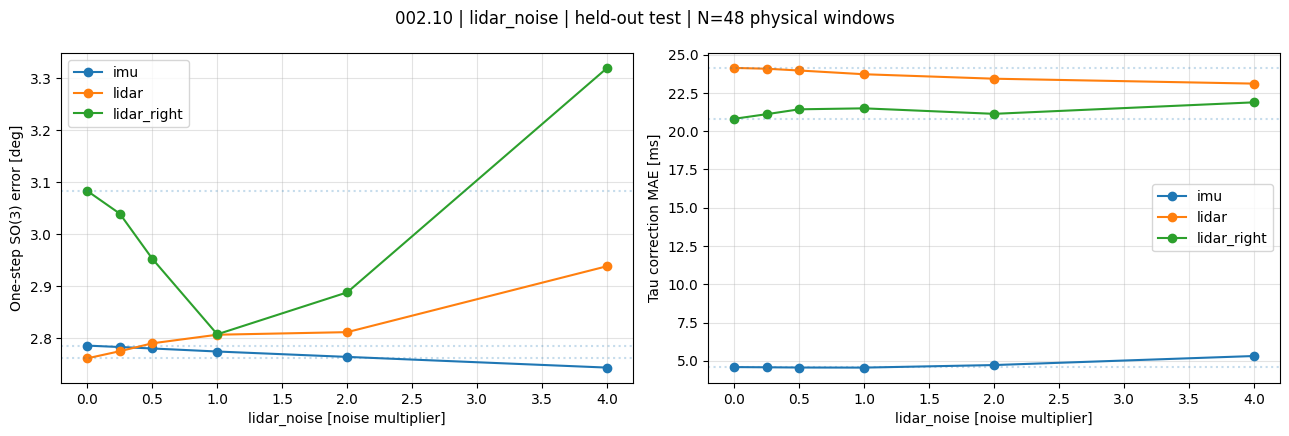

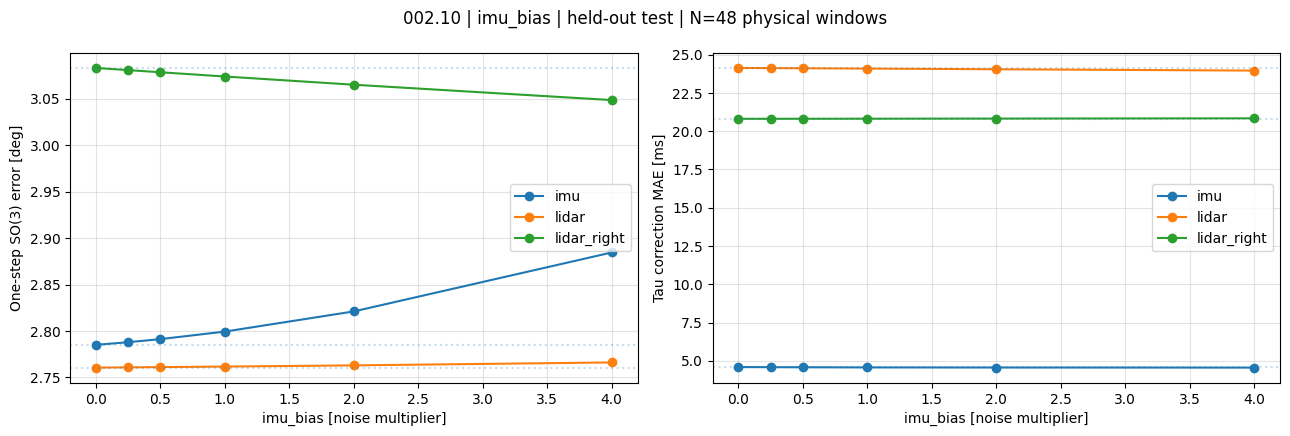

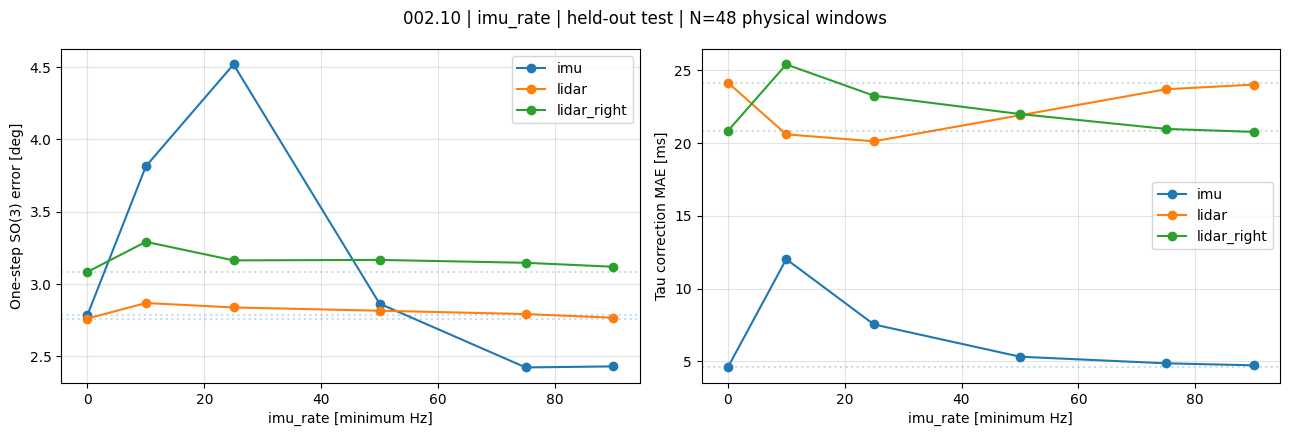

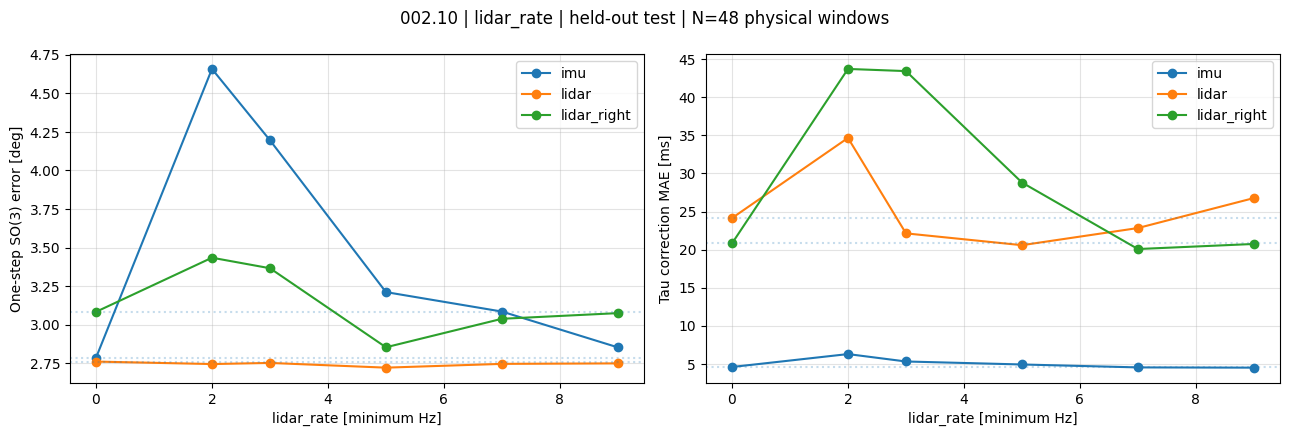

In [13]:
def plot_sweep(family, rows=ALL_RESULTS):
    chosen = [r for r in rows if r["sweep"] == family]
    if not chosen:
        raise ValueError(f"No data for {family}")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    for key in CALIBRATION_KEYS:
        sensor_rows = sorted((r for r in chosen if r["sensor"] == key), key=lambda r: r["level"])
        levels = [r["level"] for r in sensor_rows]
        for ax, field in zip(axes, ("rotation_after_deg", "tau_after_ms")):
            values = [r[field] for r in sensor_rows]
            ax.plot(levels, values, marker="o", label=key)
            ax.axhline(values[0], linestyle=":", alpha=0.25)
    axes[0].set_ylabel("One-step SO(3) error [deg]")
    axes[1].set_ylabel("Tau correction MAE [ms]")
    units = {"prior_rotation":"degrees", "prior_tau":"ms", "true_rotation":"degrees", "true_tau":"ms", "frame_rotation":"degrees", "imu_rate":"minimum Hz", "lidar_rate":"minimum Hz"}
    x_label = units.get(family, "noise multiplier")
    for ax in axes:
        ax.set_xlabel(f"{family} [{x_label}]")
        ax.grid(True, alpha=0.35)
        ax.legend()
    fig.suptitle(f"002.10 | {family} | held-out {EVAL_SPLIT} | N={len(EVAL_INDICES)} physical windows")
    fig.tight_layout()
    plt.show()

for family in SWEEPS:
    if any(r["sweep"] == family for r in ALL_RESULTS):
        plot_sweep(family)


## 12. Correction gain and out-of-distribution precision

Rotation-after may increase simply because the initial error was larger. Plot **after versus before** for prior-magnitude sweeps, along with the percentage of cases that improve. Use the exact-zero row to check false corrections. For other sweeps the fixed prior probe is unchanged, making the accuracy curves directly comparable.

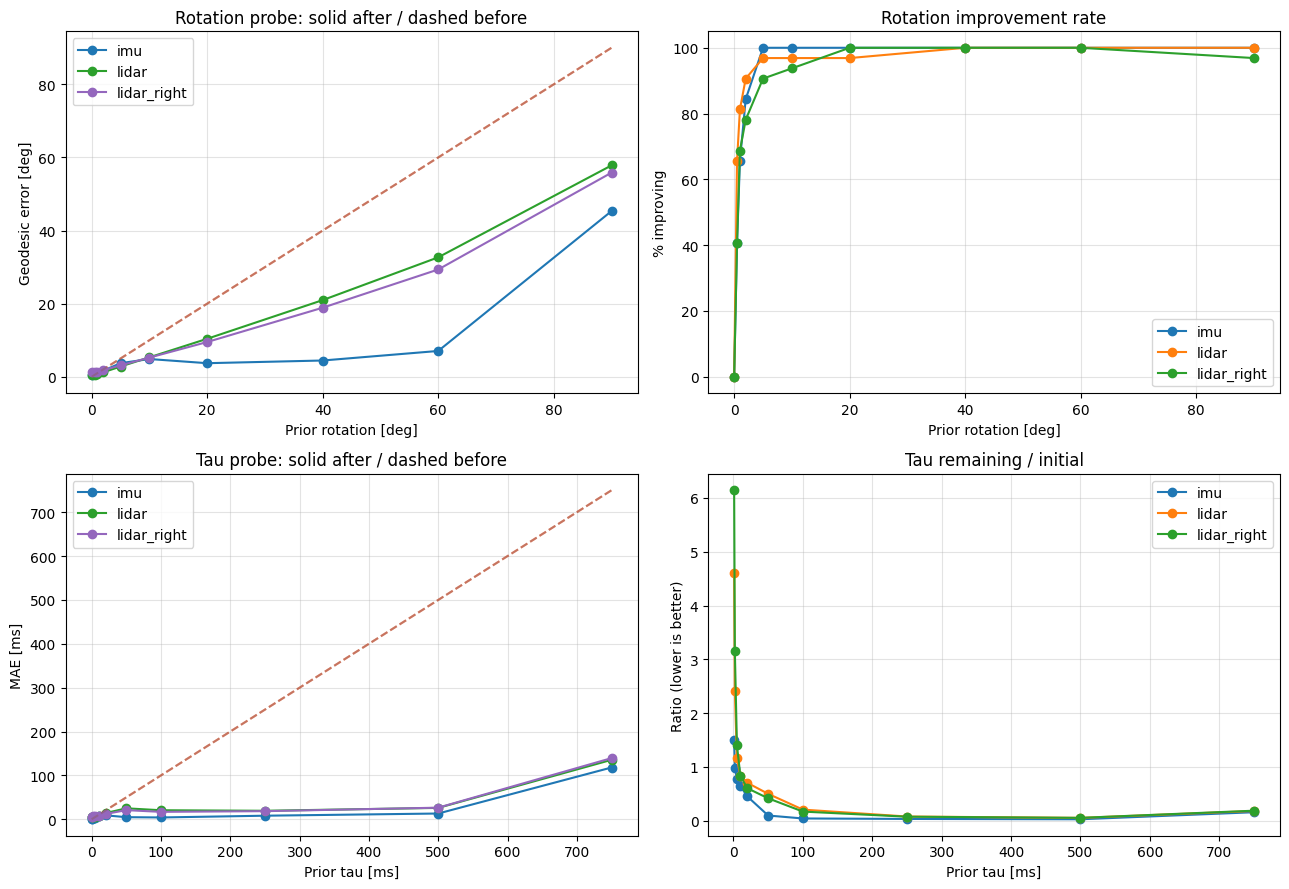

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for family, row_idx in (("prior_rotation", 0), ("prior_tau", 1)):
    for key in CALIBRATION_KEYS:
        rows = sorted((r for r in ALL_RESULTS if r["sweep"] == family and r["sensor"] == key), key=lambda r: r["level"])
        if not rows:
            continue
        if family == "prior_rotation":
            axes[row_idx, 0].plot([r["level"] for r in rows], [r["rotation_after_deg"] for r in rows], marker="o", label=key)
            axes[row_idx, 0].plot([r["level"] for r in rows], [r["rotation_before_deg"] for r in rows], linestyle="--", alpha=0.4)
            axes[row_idx, 1].plot([r["level"] for r in rows], [100 * r["rotation_improved"] for r in rows], marker="o", label=key)
        else:
            axes[row_idx, 0].plot([r["level"] for r in rows], [r["tau_after_ms"] for r in rows], marker="o", label=key)
            axes[row_idx, 0].plot([r["level"] for r in rows], [r["tau_before_ms"] for r in rows], linestyle="--", alpha=0.4)
            axes[row_idx, 1].plot([r["level"] for r in rows], [r["tau_after_ms"] / r["tau_before_ms"] if r["tau_before_ms"] > 1e-8 else float("nan") for r in rows], marker="o", label=key)
axes[0,0].set(title="Rotation probe: solid after / dashed before", xlabel="Prior rotation [deg]", ylabel="Geodesic error [deg]")
axes[0,1].set(title="Rotation improvement rate", xlabel="Prior rotation [deg]", ylabel="% improving")
axes[1,0].set(title="Tau probe: solid after / dashed before", xlabel="Prior tau [ms]", ylabel="MAE [ms]")
axes[1,1].set(title="Tau remaining / initial", xlabel="Prior tau [ms]", ylabel="Ratio (lower is better)")
for ax in axes.flat:
    ax.grid(True, alpha=0.35)
    ax.legend()
fig.tight_layout()
plt.show()


## 13. Sanity check: frame randomization versus processed tokens

Because frame randomization re-expresses raw values and the calibration together, `GeometryProcessor` should cancel the change when the prior is transformed consistently. This is a diagnostic of **representation invariance**, not a proof of arbitrary physical-mounting robustness.

In [15]:
indices = EVAL_INDICES[:min(4, len(EVAL_INDICES))]
base = window_batch_to(collate_windows([EVAL_DATASET[i] for i in indices]), DEVICE, dtype=MODEL_DTYPE)
original, _ = make_context(base, "baseline", 0, EVAL_SEED)
randomized, _ = make_context(base, "frame_rotation", 150, EVAL_SEED)
with torch.inference_mode():
    tokens_original = tokenizer(geometry_processor(original.streams, original.metadata, original.current_calibration), None)
    tokens_randomized = tokenizer(geometry_processor(randomized.streams, randomized.metadata, randomized.current_calibration), None)
    assert torch.equal(tokens_original.token_mask, tokens_randomized.token_mask)
    valid = tokens_original.token_mask
    difference_rms = (tokens_original.x[valid] - tokens_randomized.x[valid]).square().mean().sqrt().item()
    signal_rms = tokens_original.x[valid].square().mean().sqrt().item()
print(f"Exact frame relabeling 150°: token relative RMS change = {difference_rms / max(signal_rms, 1e-12):.4e}")
print("Near-zero result means frame randomization does not add new canonicalized information.")


Exact frame relabeling 150°: token relative RMS change = 2.3640e-07
Near-zero result means frame randomization does not add new canonicalized information.


## 14. Numerical summary, storage, and training decision

The table prints relative deterioration against each sweep's level-zero baseline. Use it to choose *one or two* training augmentations where a repeatable degradation appears; not every degradation requires a training run. The raw per-sensor rows are optionally saved as CSV plus a JSON run snapshot.

In [16]:
def print_robustness_summary():
    print(f"{'sweep':17s} {'sensor':12s} {'max level':>10s} {'Δrot [deg]':>12s} {'Δtau [ms]':>12s} {'rot after':>11s} {'tau after':>10s}")
    for family in SWEEPS:
        for key in CALIBRATION_KEYS:
            sample = sorted((r for r in ALL_RESULTS if r["sweep"] == family and r["sensor"] == key), key=lambda r: r["level"])
            if len(sample) < 2:
                continue
            first, last = sample[0], sample[-1]
            print(f"{family:17s} {key:12s} {last['level']:10g} {last['rotation_after_deg']-first['rotation_after_deg']:+12.3f} {last['tau_after_ms']-first['tau_after_ms']:+12.3f} {last['rotation_after_deg']:11.3f} {last['tau_after_ms']:10.3f}")

print_robustness_summary()

if SAVE_RESULTS:
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    fields = list(ALL_RESULTS[0])
    with (RESULTS_DIR / "augmentation_robustness.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(ALL_RESULTS)
    snapshot = {
        "source_checkpoint": str(RESUME_CHECKPOINT),
        "evaluation_split": EVAL_SPLIT,
        "sequences": EVAL_NAMES,
        "window_indices": EVAL_INDICES,
        "evaluation_batch_size": EVAL_BATCH_SIZE,
        "probe_rotation_deg": PROBE_ROTATION_DEG,
        "probe_tau_ms": PROBE_TAU_MS,
        "seed": EVAL_SEED,
        "sweeps": {key: list(value) for key, value in SWEEPS.items()},
        "notes": "One augmentation varied at a time; exact-angle physical/frame tests; symmetric fixed prior pairs. Rate floor is not realized frequency. Translation not supervised.",
    }
    with (RESULTS_DIR / "experiment_snapshot.json").open("w", encoding="utf-8") as stream:
        json.dump(snapshot, stream, indent=2)
    print("Saved diagnostics to:", RESULTS_DIR)


sweep             sensor        max level   Δrot [deg]    Δtau [ms]   rot after  tau after
prior_rotation    imu                  90      +44.829      +83.104      45.320     84.422
prior_rotation    lidar                90      +57.416      +46.818      57.822     51.310
prior_rotation    lidar_right          90      +54.637      +42.704      55.836     48.756
prior_tau         imu                 750       +3.284     +116.687       3.775    118.005
prior_tau         lidar               750       +1.356     +130.994       1.762    135.487
prior_tau         lidar_right         750       +1.070     +133.312       2.269    139.363
true_rotation     imu                 180       -0.000       +0.000       2.785      4.588
true_rotation     lidar               180       +0.000       -0.000       2.761     24.136
true_rotation     lidar_right         180       -0.001       +0.000       3.083     20.812
true_tau          imu                 100       +0.000       -0.000       2.785      4.588

## 15. Interpretation and follow-up

The highest-value outcome is *not* a small difference in normalized training loss. It is a clear boundary where correction quality degrades under conditions that could occur in deployment.

- **Flat frame-randomization curve + near-zero token difference:** physical frame re-expression is already handled by canonical geometry. More frame-randomization training is unlikely to add useful input variation.
- **Noise/rate degradation:** train with that augmentation only after verifying realistic sensor magnitudes. Rate augmentation can alter the number of tokens and the LiDAR motion intervals, unlike coordinate relabeling.
- **True-calibration robustness flat through 180°:** supports staying on `002.10` rather than expensive true180 fine-tuning.
- **Small prior errors:** prioritize false corrections and the after/before error ratio, rather than raw MAE alone. A small error can be made worse by an inappropriate update.
- **Large prior errors:** failures at isolated weak axes need an observability/representation diagnosis, not simply more large-angle samples.

If robustness is already satisfactory, the next evaluation should compare **single-window correction versus sequential rollout**, on matched held-out trajectories, including behavior at exact truth and after the error has shrunk close to zero. Never apply predicted translation updates from this checkpoint.
